In [1]:
# Настройка проекта
import meep as mp
import conf
import numpy as np
from lib import numpy_functions as nf
from lib import my_sources
mp.verbosity(0) # decrease amount of outputs

1

FloatProgress(value=0.0, description='0% done ', max=400.0)

max Ez = 501.21631537348816


/home/eduser/pycharm/meta-neural-sci/meta-neural-sci_mvp/lib/numpy_functions.py:56: RuntimeWarning: overflow encountered in cosh
  return a * np.cosh((x - x0) / a)


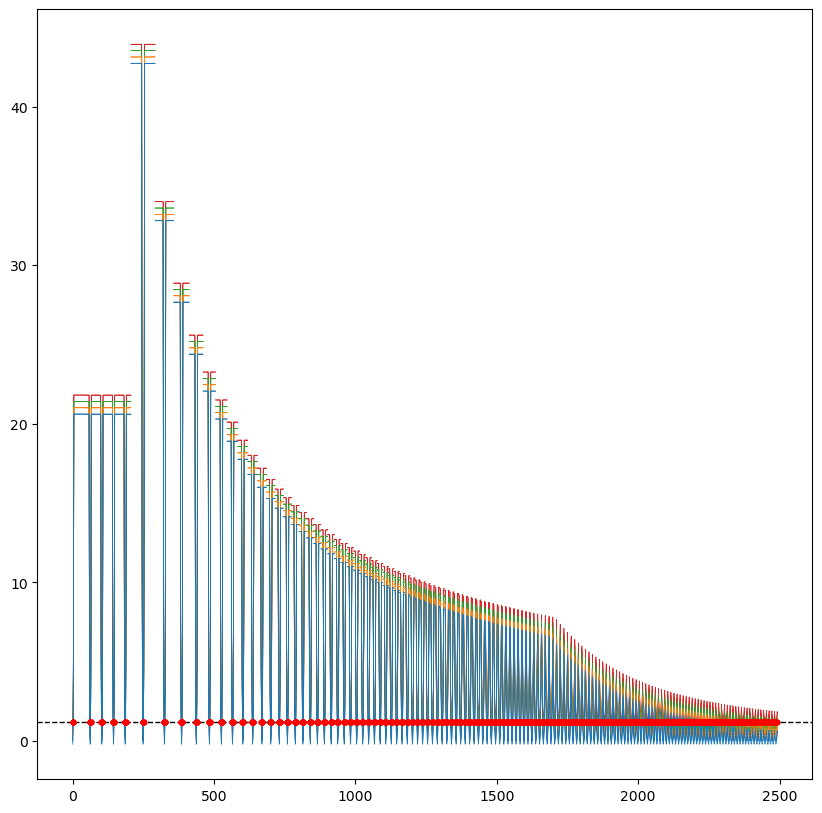

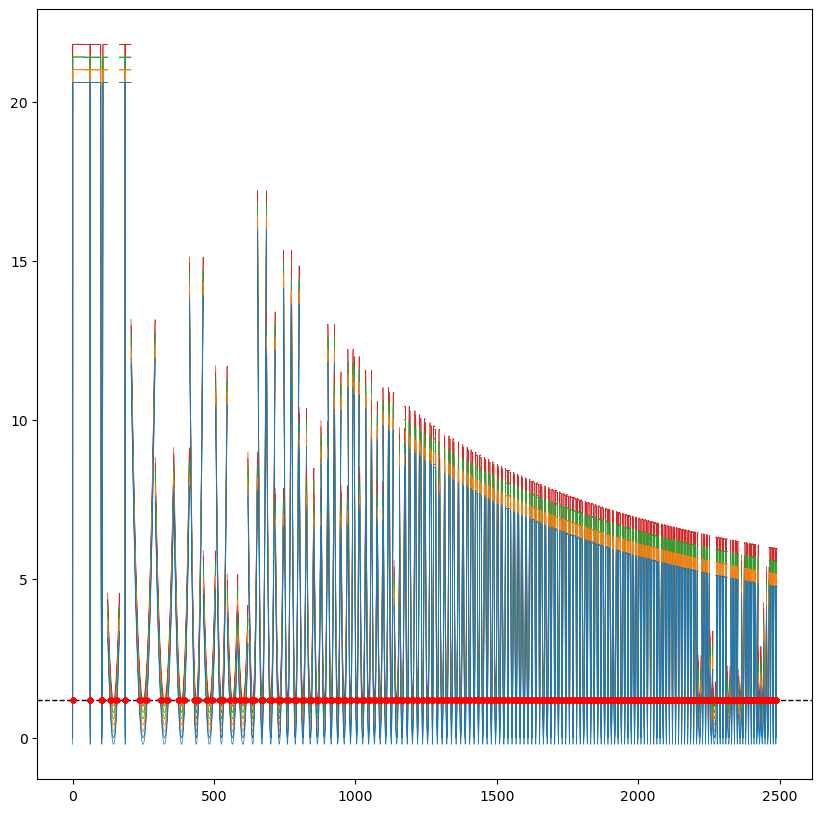

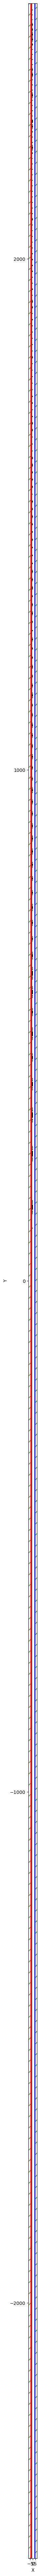

FloatProgress(value=0.0, description='0% done ', max=400.0)

max Ez = 2994.4254169407595


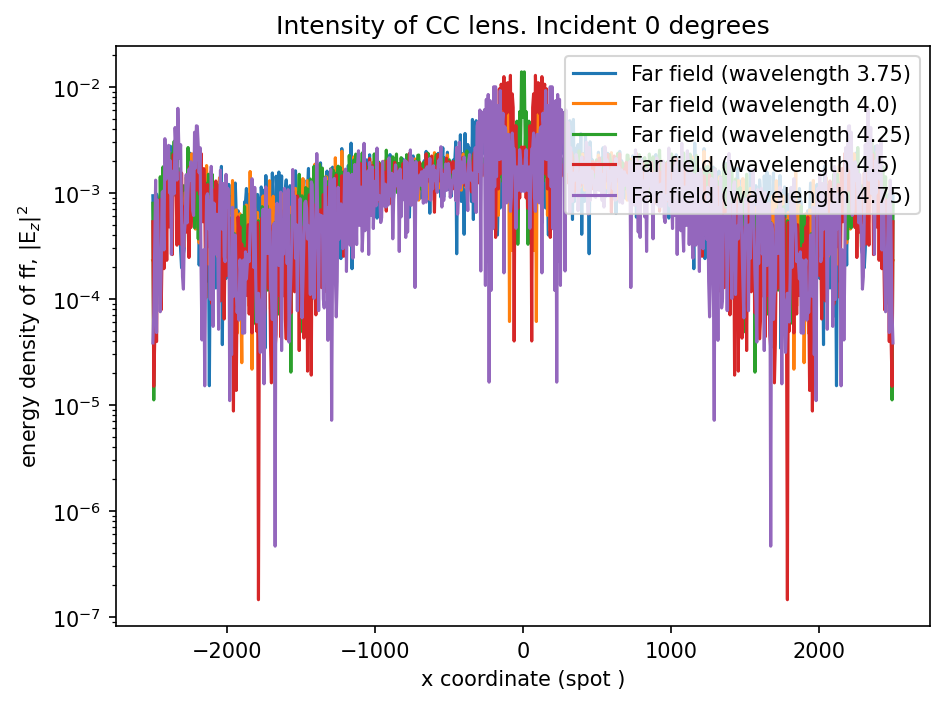

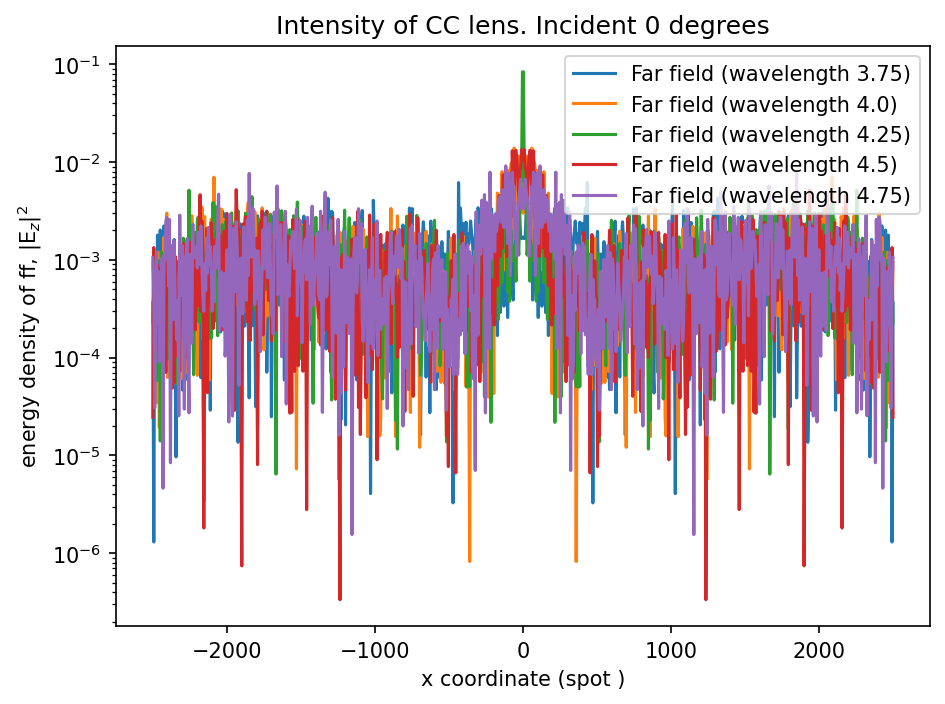

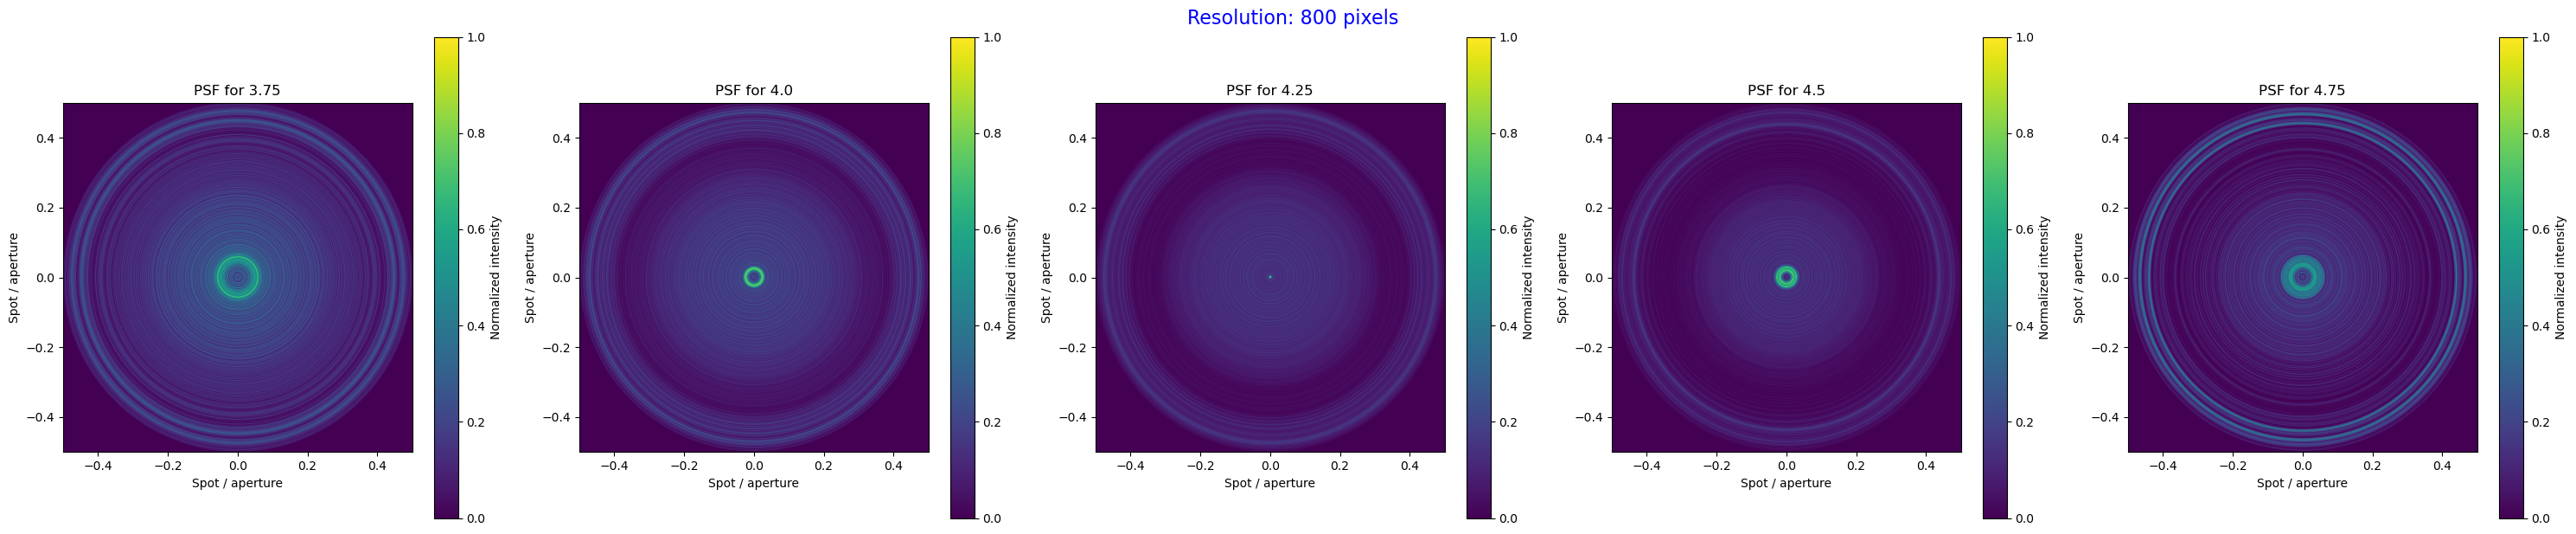

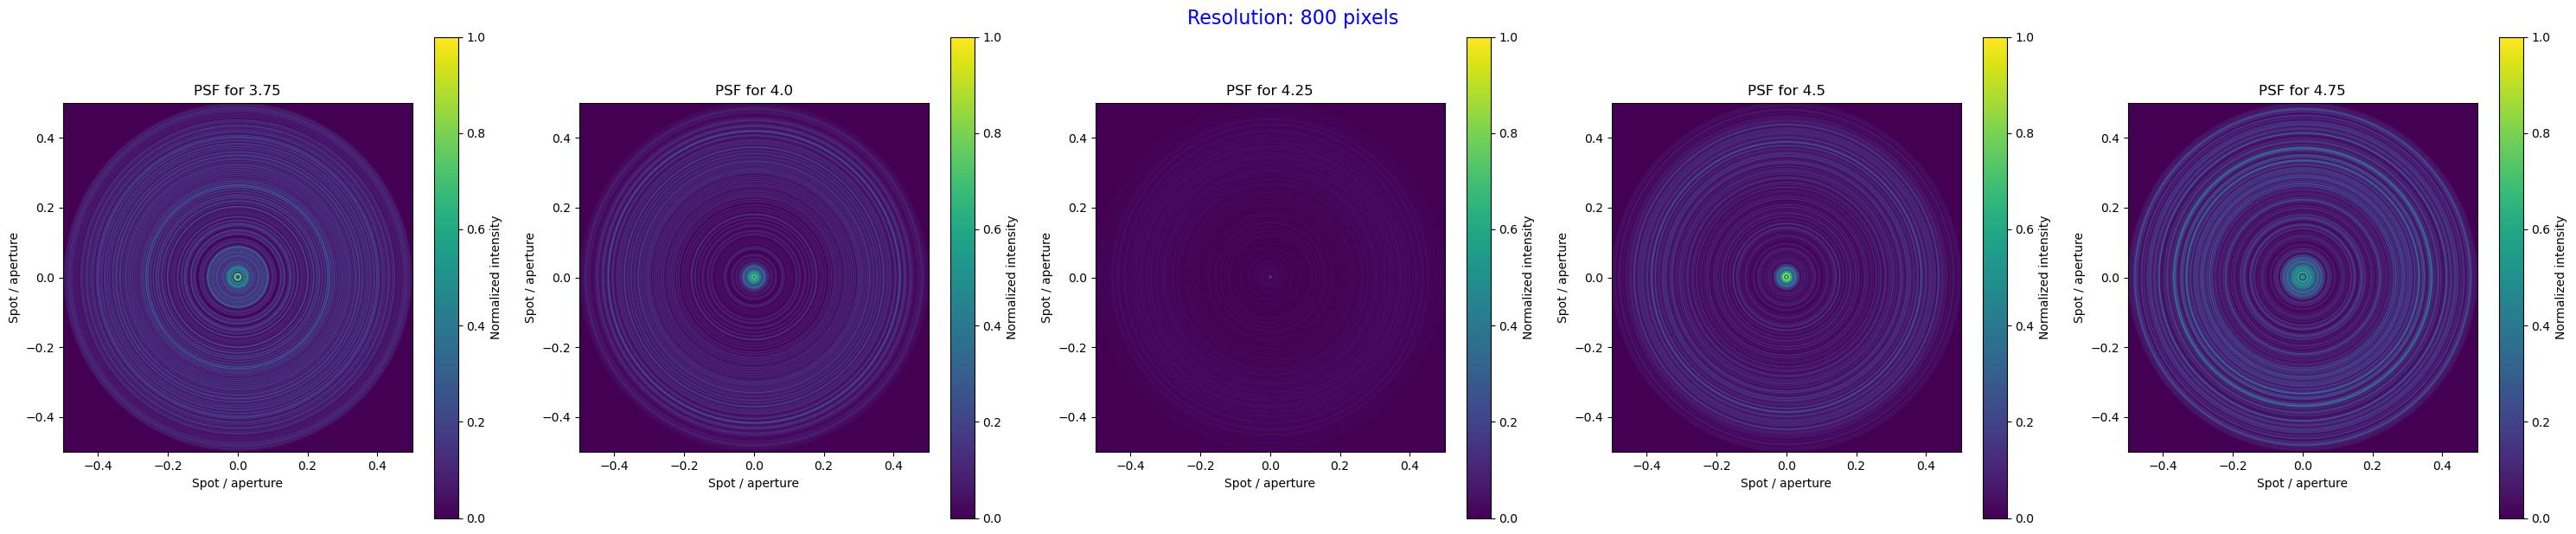

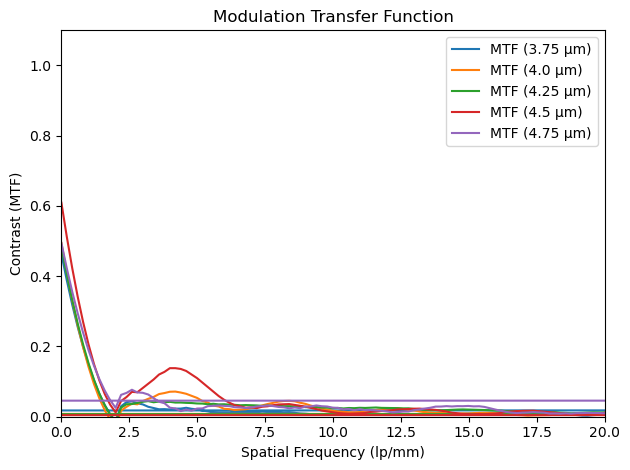

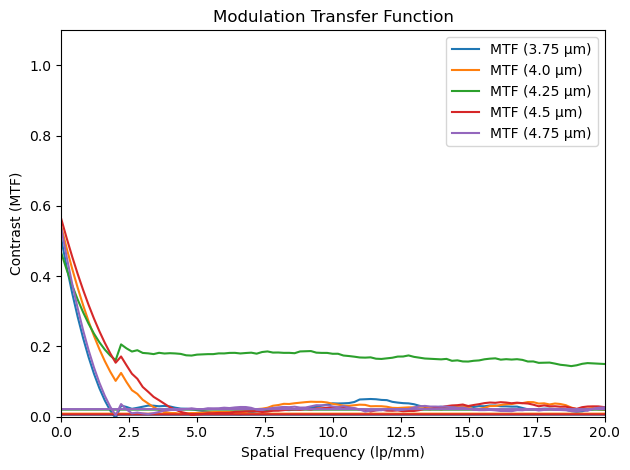

Initial FOM / Opt FOM  0.021449132202164673 / 0.05364544464603342 
Initial output max Izyx_fp: 0.006587637174095654
Opt output max Izyx_fp is: 0.009626721650041758
Initial output max Izyx_fp: 0.00876501064981613
Opt output max Izyx_fp is: 0.013918769892832554
Initial output max Izyx_fp: 0.013800072391587747
Opt output max Izyx_fp is: 0.08377208214727877
Initial output max Izyx_fp: 0.012791179374090364
Opt output max Izyx_fp is: 0.013424401411086903
Initial output max Izyx_fp: 0.00999410071829985
Opt output max Izyx_fp is: 0.009157784678383003


In [2]:
"""
Инициализация
"""
angle = 0
shape_coefficient_initial = np.array([[ 1.0000,  1.0204,  1.0412,  1.0625,  1.0842,  1.1063,  1.1289,  1.1519,
         1.1754,  1.1994,  1.2239,  1.2489,  1.2743,  1.3004,  1.3269,  1.3540,
         1.3816,  1.4098,  1.4386,  1.4679,  1.4979,  1.5285,  1.5596,  1.5915,
         1.6240,  1.6571,  1.6909,  1.7254,  1.7606,  1.7966,  1.8332,  1.8706,
         1.9088,  1.9478,  1.9875,  2.0281,  2.0695,  2.1117,  2.1548,  2.1988,
         2.2437,  2.2894,  2.3362,  2.3838,  2.4325,  2.4821,  2.5328,  2.5845,
         2.6372,  2.6911,  2.7460,  2.8020,  2.8592,  2.9175,  2.9771,  3.0378,
         3.0998,  3.1631,  3.2277,  3.2935,  3.3607,  3.4293,  3.4993,  3.5707,
         3.6436,  3.7180,  3.7938,  3.8713,  3.9503,  4.0309,  4.1131,  4.1971,
         4.2827,  4.3701,  4.4593,  4.5503,  4.6432,  4.7380,  4.8347,  4.9333,
         5.0340,  5.1367,  5.2416,  5.3485,  5.4577,  5.5691,  5.6827,  5.7987,
         5.9170,  6.0378,  6.1610,  6.2868,  6.4151,  6.5460,  6.6796,  6.8159,
         6.9550,  7.0969,  7.2418,  7.3895,  7.5404,  7.6942,  7.8513,  8.0115,
         8.1750,  8.3418,  8.5121,  8.6858,  8.8630,  9.0439,  9.2285,  9.4168,
         9.6090,  9.8051, 10.0052, 10.2094, 10.4178, 10.6304, 10.8473, 11.0687,
        11.2946, 11.5251, 11.7603, 12.0003, 12.2452, 12.4951, 12.7501, 13.0103,
        13.2758, 13.5468, 13.8232, 14.1053, 14.3932, 14.6869, 14.9867, 15.2925,
        15.6046, 15.9231, 16.2480, 16.5796, 16.9180, 17.2632]]).T
shape_coefficient_opt = np.array([[1.5779e-02, 2.1255e-02, 9.0486e-01, 6.3871e+01, 1.6917e-02, 7.8249e+01,
        7.1874e+01, 4.9570e+01, 2.3373e+01, 5.2702e+01, 2.1181e+01, 4.5964e+01,
        5.3470e+01, 1.9348e+01, 9.2970e+00, 1.1184e+01, 1.7217e+01, 7.9808e+00,
        8.0182e+00, 1.0760e+01, 1.2311e+01, 1.2578e+01, 9.5485e+00, 6.6360e+00,
        7.7174e+00, 1.0362e+01, 4.6531e+00, 4.4475e+00, 8.6309e+00, 6.1217e+00,
        6.6619e+00, 8.2036e+00, 5.9996e+00, 3.2377e+00, 1.0986e+01, 6.1798e+00,
        3.2179e+00, 5.1702e+00, 3.1108e+00, 2.7274e+00, 5.2870e+00, 1.3345e+00,
        2.8113e+00, 5.5069e+00, 4.1091e+00, 2.2788e+00, 4.5982e+00, 4.0439e+00,
        3.5456e+00, 2.0658e+00, 1.9962e+00, 1.9371e+00, 2.9052e+00, 1.8681e+00,
        2.2285e+00, 3.2307e+00, 2.7130e+00, 3.1111e+00, 5.8360e-01, 2.3723e+00,
        2.4430e+00, 2.4287e+00, 3.2692e+00, 2.9280e+00, 9.4322e-01, 9.8710e-01,
        7.3982e-01, 2.6585e+00, 2.9397e+00, 1.3278e+00, 8.2187e-01, 1.5571e+00,
        1.3034e+00, 7.3049e-01, 7.7161e-01, 7.1032e-01, 6.1684e-01, 7.5693e-01,
        2.6886e+00, 8.0864e-01, 8.6159e-01, 8.7109e-01, 1.0957e+00, 1.0111e+00,
        1.5919e+00, 8.2212e-01, 2.6502e+00, 3.4808e+00, 7.9243e-01, 1.7355e+00,
        9.2873e-01, 1.0262e+00, 1.5427e+00, 1.3970e+00, 1.8115e+00, 1.2657e+00,
        9.5981e-01, 6.8642e-01, 6.3320e-01, 6.0607e-01, 7.6722e-01, 2.7941e+00,
        1.1348e+00, 8.2912e-01, 7.3181e-01, 7.9889e-01, 9.7907e-01, 6.5111e-01,
        6.9771e-01, 5.7577e-01, 7.2119e-01, 7.4332e-01, 4.6955e-01, 1.4856e+00,
        1.0005e+01, 1.0124e+00, 1.0666e+00, 1.3141e+00, 6.4447e+00, 2.3233e+01,
        6.2049e-01, 9.3065e-01, 5.6842e-01, 5.0306e-01, 1.2107e+01, 1.0913e+00,
        1.1409e+00, 7.8055e-01, 1.3276e+01, 3.2563e+00, 8.4837e-01, 9.6249e-01,
        6.4410e-01, 5.6831e-01, 2.7330e+00, 7.2520e+00, 7.5277e+00, 4.2395e+00,
        3.2876e+00, 5.3831e-01, 7.0714e-01, 9.7915e-01]]).T

sources_obj = my_sources.KvectorSource(frequency=conf.inc_fcen, y=conf.cell_Y, angle=angle)
sources = sources_obj.get_sources()
k_point=sources_obj.get_k_vector()
ff_res = conf.resolution_base/conf.spot_ff

geometry = []
geometry = nf.infill_geometry(shape_coefficient_initial, geometry)
sim, near2far = nf.setup_simulation(geometry, sources, k_point, df = conf.inc_df, nfreq = conf.inc_nfreq, plot =  False)
sim.run(until=conf.maximum_run_time)
initial_Izyx_fp = nf.get_Izyx(sim, near2far,ff_res, mp.Vector3(0, conf.spot_ff, 0), angle = angle)  #Intensity in Focal Plane
init_FOM = nf.get_FOM_main(conf.spot_ff, initial_Izyx_fp)
sim.reset_meep()

geometry = []
geometry = nf.infill_geometry(shape_coefficient_opt, geometry)
sim, near2far = nf.setup_simulation(geometry, sources, k_point, df = conf.inc_df, nfreq = conf.inc_nfreq, plot =  True)
sim.run(until=conf.maximum_run_time)
opt_Izyx_fp = nf.get_Izyx(sim, near2far,ff_res, mp.Vector3(0, conf.spot_ff, 0), angle = angle)  #Intensity in Focal Plane
opt_FOM = nf.get_FOM_main(conf.spot_ff, opt_Izyx_fp)


# Intensity plot
nf.get_plot_intensity(conf.spot_ff, initial_Izyx_fp)
nf.get_plot_intensity(conf.spot_ff, opt_Izyx_fp)

# PSF
nf.plot_psf(conf.inc_nfreq, conf.spot_ff, initial_Izyx_fp)
nf.plot_psf(conf.inc_nfreq, conf.spot_ff, opt_Izyx_fp)
# nf.plot_psf_tilt(
#     nfrec = conf.inc_nfreq,
#     spot_ff = conf.spot_ff,
#     I = opt_Izyx_fp,
#     theta = np.radians(angle),
#     f = conf.f,
#     width_x= 0.1,
#     field_extent= 10e3,
#     relation = "abs",
# )
# MTF 
nf.plot_mtf(conf.spot_ff, initial_Izyx_fp, smooth = True)
nf.plot_mtf(conf.spot_ff, opt_Izyx_fp, smooth = True)
print(f"Initial FOM / Opt FOM  {init_FOM} / {opt_FOM} ")

if len(initial_Izyx_fp.shape) == 1:
    print(f"Initial output max Izyx_fp: {max(initial_Izyx_fp)} || FOM: {init_FOM}")
    print(f"Opt output max Izyx_fp is: {max(opt_Izyx_fp)} || FOM: {opt_FOM}")
else:
        for i in range (initial_Izyx_fp.shape[1]):
            print(f"Initial output max Izyx_fp: {max(initial_Izyx_fp[:,i])}")
            print(f"Opt output max Izyx_fp is: {max(opt_Izyx_fp[:,i])}")